# Consumer Complaint Trends and Response Intelligence Platform
## A. Data Quality Assessment
### Objective
Inspect and validate the consumer complaints dataset before performing analysis and dashboard development.
### 1. Dataset Overview

### 2. Complaint ID Validation

### 3. Handling Duplicate Records

### 4. Handling Missing Values

### 5. Date Validation

### 6. Standardizing Categorical Values

### 7. Investigating unusual or inconsistent values

## B. Feature Engineering
### Year
### Month
### Quarter
### Day

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [ ]:
print("pandas loaded successfully")

pandas loaded successfully


In [8]:
df = pd.read_excel("C:/Users/totes/Documents/AnalystLab Africa/Week 4 Task/Consumer_Complaints_Week4/data/Consumer_Complaints.xlsx")

df.head()

,Complaint ID,Submitted via,Date submitted,Date received,State,Product,Sub-product,Issue,Sub-issue,Company public response,Company response to consumer,Timely response?
0,4848023,Referral,2021-10-24,2021-10-27,NY,Mortgage,Conventional home mortgage,Applying for a mortgage or refinancing an exis...,NaN,Company has responded to the consumer and the ...,Closed with explanation,Yes
1,3621464,Web,2020-04-24,2020-04-24,FL,"Money transfer, virtual currency, or money ser...",Refund anticipation check,Lost or stolen check,NaN,Company has responded to the consumer and the ...,Closed with monetary relief,Yes
2,5818349,Web,2022-07-27,2022-07-27,CA,"Credit reporting, credit repair services, or o...",Credit reporting,Incorrect information on your report,Account information incorrect,Company has responded to the consumer and the ...,Closed with explanation,Yes
3,7233015,Referral,2023-07-10,2023-07-11,CA,Credit card or prepaid card,General-purpose prepaid card,Problem getting a card or closing an account,"Trouble getting, activating, or registering a ...",NaN,In progress,NaN
4,5820224,Referral,2022-07-27,2022-07-28,VA,Credit card or prepaid card,General-purpose credit card or charge card,Closing your account,Company closed your account,Company has responded to the consumer and the ...,Closed with explanation,Yes


### 1. Dataset Overview

In this section, the dataset structure, dimensions, and data types are inpected before performing data cleaning and analysis.

In [10]:
df.shape

(62516, 12)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 62516 entries, 0 to 62515
Data columns (total 12 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   Complaint ID                  62516 non-null  int64         
 1   Submitted via                 62516 non-null  str           
 2   Date submitted                62516 non-null  datetime64[us]
 3   Date received                 62516 non-null  datetime64[us]
 4   State                         62516 non-null  str           
 5   Product                       62516 non-null  str           
 6   Sub-product                   62509 non-null  str           
 7   Issue                         62516 non-null  str           
 8   Sub-issue                     51658 non-null  str           
 9   Company public response       60341 non-null  str           
 10  Company response to consumer  62516 non-null  str           
 11  Timely response?              61022 non

In [13]:
print(df.columns.tolist())

['Complaint ID', 'Submitted via', 'Date submitted', 'Date received', 'State', 'Product', 'Sub-product', 'Issue', 'Sub-issue', 'Company public response', 'Company response to consumer', 'Timely response?']


### Findings

- The dataset contains 62,516 rows and 12 columns.
- The complaint records were inspected to verify the column names and data types before data cleaning.

### 2. Complaint ID Validation
The complaint ID column is assessed to determine whether it can be used as a unique identifier for each complaint record.

In [18]:
print("Total Records:", len(df))

Total Records: 62516


In [16]:
df["Complaint ID"].nunique()

62516

In [17]:
df["Complaint ID"].duplicated().sum()

np.int64(0)

### Findings
The dataset contains 62,516 complaint records and unique complaint IDs. No duplicates were identified in the dataset. Therefore, Complaint ID can be used as the primary key and unique identifier for the dataset.

### 3. Handling Duplicate Records
This section identifies whether duplicate records exits within the dataset.

In [20]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


### Findings:
No duplicate records were identified within the dataset. Each complaint observation is unique.

### 4. Handling Missing Values
This section identifies fields containing missing values and their impact on the analysis.

In [21]:
df.isnull().sum()

Complaint ID                        0
Submitted via                       0
Date submitted                      0
Date received                       0
State                               0
Product                             0
Sub-product                         7
Issue                               0
Sub-issue                       10858
Company public response          2175
Company response to consumer        0
Timely response?                 1494
dtype: int64

### Findings:
Missing values were identified in the following fields:
- Sub-product = 7
- Sub-issue = 10,858
- Company public response = 2,175
- Timely response = 1,494

No missing values were identified in the remaining fields.

### 5. Date Validation
This section aims to validate the date fields and identify any inconsistencies. According to the dataset, date submitted represents when CFPB received the complaint, and date received represents when CFPB forwarded the complaint to Bank of America. Therefore, Date received should occur on or after date submitted.

### Forwarding Interval Calculation
This aims to calculate the number of days it takes for CFPB to forward the complaint to the bank of America after recieving it.

In [25]:
print("Earliest Date Submitted:", df["Date submitted"].min())
print("Latest Date Submitted:", df["Date submitted"].max())

print("Earliest Date Received:", df["Date received"].min())
print("Latest Date Received:", df["Date received"].max())

Earliest Date Submitted: 2017-05-01 00:00:00
Latest Date Submitted: 2023-08-28 00:00:00
Earliest Date Received: 2017-05-01 00:00:00
Latest Date Received: 2023-08-28 00:00:00


In [27]:
invalid_dates = df[df["Date received"] < df["Date submitted"]]
len(invalid_dates)

0

In [28]:
df["Forwarding Interval"] = (df["Date received"] - df["Date submitted"]).dt.days

In [29]:
df[["Date submitted","Date received", "Forwarding Interval"]].head()

,Date submitted,Date received,Forwarding Interval
0,2021-10-24,2021-10-27,3
1,2020-04-24,2020-04-24,0
2,2022-07-27,2022-07-27,0
3,2023-07-10,2023-07-11,1
4,2022-07-27,2022-07-28,1


In [30]:
df["Forwarding Interval"].describe()

count    62516.000000
mean         1.224886
std          5.649298
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        275.000000
Name: Forwarding Interval, dtype: float64

### Findings:
This confirms that the analysis period runs from 01 May 2017 to 28 August 2023. No invalid dates were identified in the dataset.

A forwarding interval column was created to measure the number of days it takes for the CFPB to forward the complaints to the Bank of America.

### 6. Standardizing Categorical Values
This section identifies and corrects any inconsistencies in the dataset's categorical fields.

In [34]:
df["Submitted via"].value_counts()

Submitted via
Web             45423
Referral        10766
Phone            4684
Postal mail      1318
Fax               233
Web Referral       90
Email               2
Name: count, dtype: int64

In [35]:
df["Product"].value_counts()

Product
Checking or savings account                                                     24814
Credit card or prepaid card                                                     16197
Credit reporting, credit repair services, or other personal consumer reports     7710
Mortgage                                                                         6601
Money transfer, virtual currency, or money service                               3453
Debt collection                                                                  2736
Vehicle loan or lease                                                             633
Payday loan, title loan, or personal loan                                         333
Student loan                                                                       39
Name: count, dtype: int64

In [37]:
df["Company response to consumer"].value_counts()

Company response to consumer
Closed with explanation            41044
Closed with monetary relief        14697
Closed with non-monetary relief     5273
In progress                         1494
Closed                                 8
Name: count, dtype: int64

In [45]:
df["State"].value_counts()

State
CA    13709
FL     6488
TX     4686
NY     4442
GA     2921
NJ     2664
IL     2270
MA     2141
MD     1959
VA     1731
NC     1717
PA     1676
WA     1530
AZ     1516
MI     1395
NV     1221
CT     1097
SC      822
TN      758
OH      731
MO      674
OR      620
CO      576
MN      382
DC      353
IN      316
KS      311
OK      293
WI      291
AL      269
DE      268
AR      266
RI      249
LA      246
NM      219
UT      201
NH      199
KY      157
IA      154
ME      152
MS      141
ID      122
HI      111
AK      110
NE       83
WV       77
MT       70
VT       54
SD       34
ND       22
WY       22
Name: count, dtype: int64

In [39]:
df["Timely response?"].value_counts(dropna=False)

Timely response?
Yes    58619
No      2403
NaN     1494
Name: count, dtype: int64

### Findings
- No errors were found in the categorical fields after standardization.
- For timely response: 1494 records are missing.

### 7. Investigating unusual or inconsistent values 

This section identifies unusual or inconsistent values to prevent data quality issues.

In [42]:
df[df["Forwarding Interval"] < 0]

,Complaint ID,Submitted via,Date submitted,Date received,State,Product,Sub-product,Issue,Sub-issue,Company public response,Company response to consumer,Timely response?,Forwarding Interval


In [44]:
sorted(df["Product"].unique())

['Checking or savings account',
 'Credit card or prepaid card',
 'Credit reporting, credit repair services, or other personal consumer reports',
 'Debt collection',
 'Money transfer, virtual currency, or money service',
 'Mortgage',
 'Payday loan, title loan, or personal loan',
 'Student loan',
 'Vehicle loan or lease']

In [55]:
sorted(df["State"].unique())

['AK',
 'AL',
 'AR',
 'AZ',
 'CA',
 'CO',
 'CT',
 'DC',
 'DE',
 'FL',
 'GA',
 'HI',
 'IA',
 'ID',
 'IL',
 'IN',
 'KS',
 'KY',
 'LA',
 'MA',
 'MD',
 'ME',
 'MI',
 'MN',
 'MO',
 'MS',
 'MT',
 'NC',
 'ND',
 'NE',
 'NH',
 'NJ',
 'NM',
 'NV',
 'NY',
 'OH',
 'OK',
 'OR',
 'PA',
 'RI',
 'SC',
 'SD',
 'TN',
 'TX',
 'UT',
 'VA',
 'VT',
 'WA',
 'WI',
 'WV',
 'WY']

### Findings:
No unusual or inconsistent values were identified.

## Feature Engineering
This section aims to extract the date fields into separate fields: Year, Month, Quarter, and Day

In [47]:
df["Year"] = df["Date submitted"].dt.year

df["Year"].head()

0    2021
1    2020
2    2022
3    2023
4    2022
Name: Year, dtype: int32

In [48]:
df["Month Number"] = df["Date submitted"].dt.month
df["Month Number"].head()

0    10
1     4
2     7
3     7
4     7
Name: Month Number, dtype: int32

In [52]:
df["Month"] = df["Date submitted"].dt.month_name()

df["Month"].head()

0    October
1      April
2       July
3       July
4       July
Name: Month, dtype: str

In [49]:
df["Quarter"] = "Q" + df["Date submitted"].dt.quarter.astype(str)
df["Quarter"].head()

0    Q4
1    Q2
2    Q3
3    Q3
4    Q3
Name: Quarter, dtype: str

In [53]:
df[
    [
        "Date submitted",
        "Year",
        "Quarter",
        "Month Number",
        "Month"
    ]
].head()

,Date submitted,Year,Quarter,Month Number,Month
0,2021-10-24,2021,Q4,10,October
1,2020-04-24,2020,Q2,4,April
2,2022-07-27,2022,Q3,7,July
3,2023-07-10,2023,Q3,7,July
4,2022-07-27,2022,Q3,7,July


### Features were successfully extracted from the date field.

## EDA
This section explores the complaint trends, product distribution, response patterns, and forwarding intervals to generate meaningful insights.

### 1. How Have Complaint Volumes Changed Over Time?

In [56]:
annual_complaints = (
    df.groupby("Year")["Complaint ID"].count()
    .reset_index(name="Complaints")
)
annual_complaints

,Year,Complaints
0,2017,5394
1,2018,7872
2,2019,7075
3,2020,8942
4,2021,11149
5,2022,12953
6,2023,9131


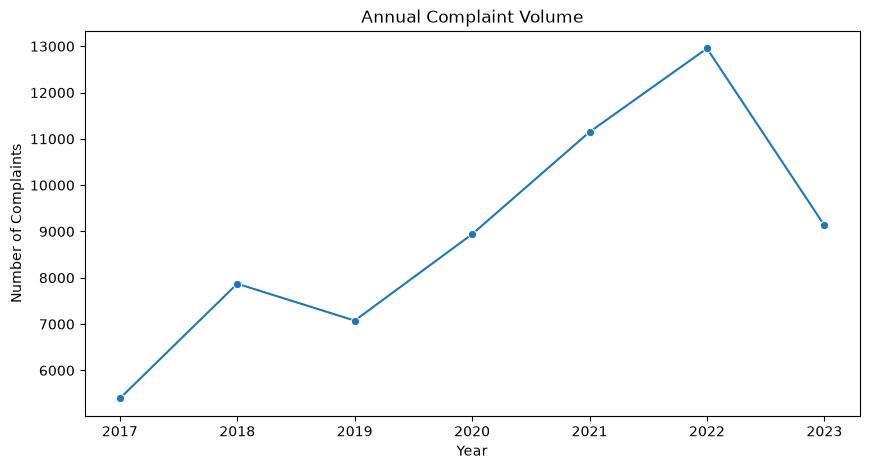

In [ ]:
plt.figure(figsize=(10,5))

sns.lineplot(
    data=annual_complaints,
    x="Year",
    y="Complaints",
    marker="o"
)

plt.title("Annual Complaint Volume")
plt.xlabel("Year")
plt.ylabel("Number of Complaints")

plt.show()

There was an increase in complaint volume from 2017 to 2022. However, in 2022, a sharp decrease in complaint volume occured until 2023.

### Which Products Have the Most Complaints?

In [65]:
top_products = (
    df["Product"]
      .value_counts()
      .reset_index()
)

top_products.head(10)

,Product,count
0,Checking or savings account,24814
1,Credit card or prepaid card,16197
2,"Credit reporting, credit repair services, or o...",7710
3,Mortgage,6601
4,"Money transfer, virtual currency, or money ser...",3453
5,Debt collection,2736
6,Vehicle loan or lease,633
7,"Payday loan, title loan, or personal loan",333
8,Student loan,39


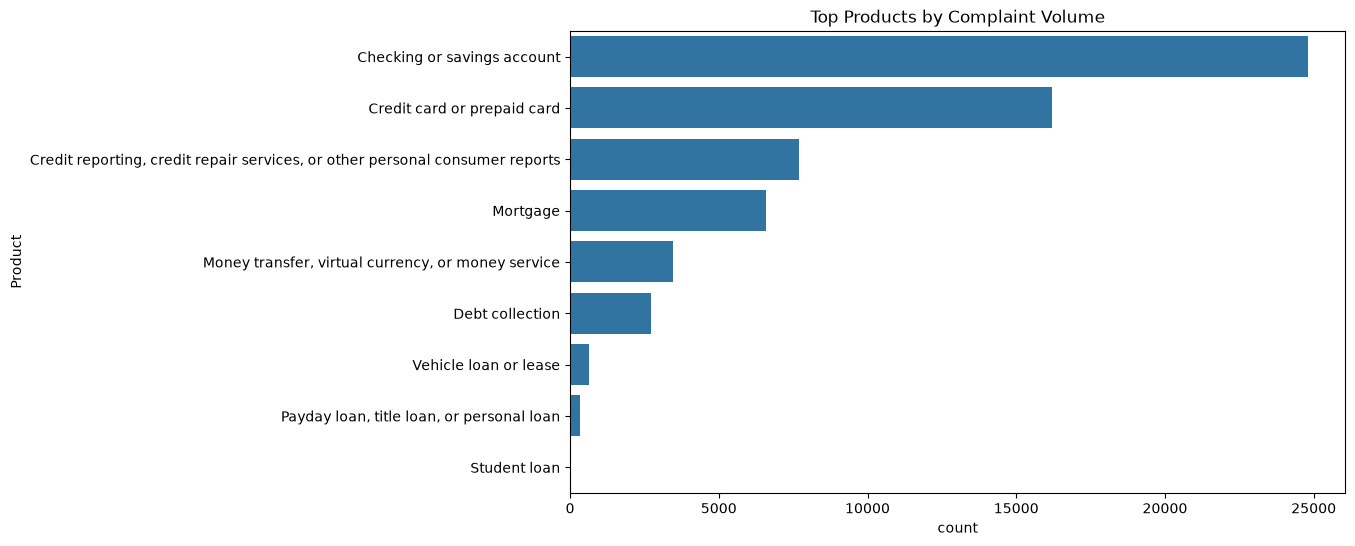

In [66]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=top_products.head(10),
    x="count",
    y="Product"
)

plt.title("Top Products by Complaint Volume")

plt.show()

Checking/savings account and credit/prepaid card are th eproducts with the most complaints. Meanwhile, student loan products received zero complaints from consumers during the analysis period.

### What are the most common complaints received from consumers

In [67]:
top_issues = (
    df["Issue"]
      .value_counts()
      .reset_index()
)

top_issues.head(10)

,Issue,count
0,Managing an account,15109
1,Incorrect information on your report,4931
2,Problem with a purchase shown on your statement,4415
3,Closing an account,2953
4,Trouble during payment process,2827
5,Opening an account,2725
6,Problem with a lender or other company chargin...,2493
7,Fraud or scam,1987
8,Struggling to pay mortgage,1904
9,Problem with a credit reporting company's inve...,1876


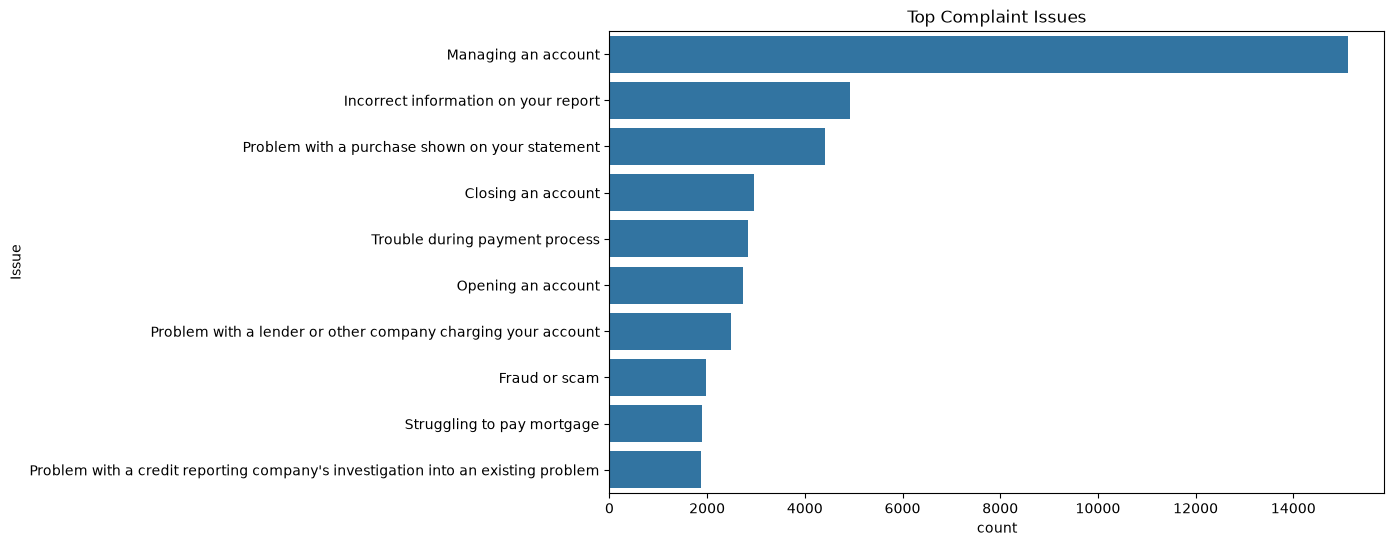

In [68]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=top_issues.head(10),
    x="count",
    y="Issue"
)

plt.title("Top Complaint Issues")

plt.show()

Managing an account was the most common complaint the CFPB received about the Bank of America. 

### What Is the Timely Response Rate?

In [69]:
timely_counts = (
    df["Timely response?"]
      .value_counts(dropna=False)
)

timely_counts

Timely response?
Yes    58619
No      2403
NaN     1494
Name: count, dtype: int64

In [72]:
valid_records = df[
    df["Timely response?"].isin(["Yes","No"])
]

timely_response_pct = (
    (valid_records["Timely response?"] == "Yes")
    .mean()
    * 100
)

timely_response_pct

np.float64(96.06207597260004)

In [80]:
df["Timely response?"].isna().sum()

np.int64(1494)

The timely response rate is 96.06%. 

### What Is the Average Forwarding Interval?

In [73]:
df["Forwarding Interval"].describe()

count    62516.000000
mean         1.224886
std          5.649298
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        275.000000
Name: Forwarding Interval, dtype: float64

In [74]:
df["Forwarding Interval"].mean()

np.float64(1.224886429074157)

In [78]:
df["Forwarding Interval"].median()

np.float64(0.0)

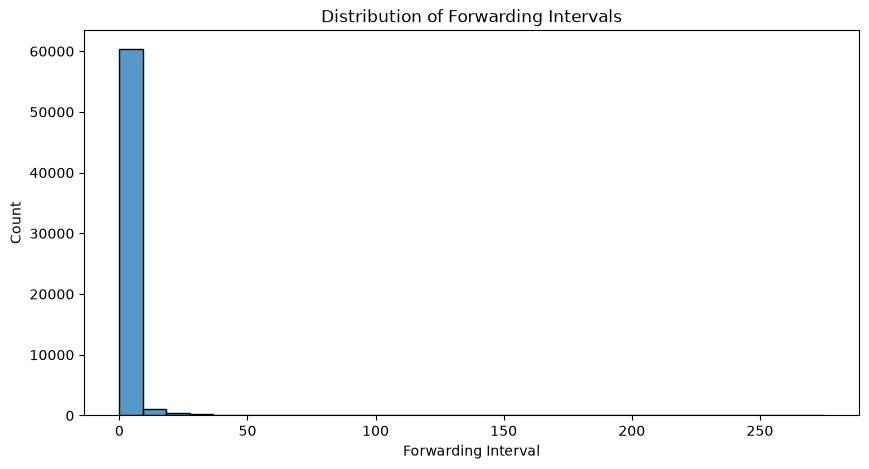

In [81]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x="Forwarding Interval",
    bins=30
)

plt.title("Distribution of Forwarding Intervals")

plt.show()

Export Cleaned Dataset

In [82]:
df.to_excel(
    "../outputs/Consumer_Complaints_Cleaned.xlsx",
    index=False
)

print("Cleaned dataset exported successfully.")

Cleaned dataset exported successfully.
